In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [ ]:
df = sns.load_dataset("tips")   # restaurant bills
df.head()


In [ ]:
# sns.scatterplot(
#     data=df, x="total_bill", y="tip",
#     # hue="smoker",     # colour  -> smoker
#     # style="size",      # shape   -> sex
#     col="time",      # size    -> party size
# )
# plt.show()

In [ ]:
sns.relplot(data=df, x="total_bill", y="tip", kind="scatter", col="sex", hue ="smoker")
plt.show()


In [ ]:
sns.histplot(data=df, x="total_bill", kde = True)
plt.show()

In [ ]:
sns.kdeplot(data=df, x="total_bill", fill=True)
plt.show()

In [ ]:
sns.ecdfplot(data=df, x="total_bill")
plt.show()

In [ ]:
df['price_range'] = pd.cut(df['total_bill'], [0,10, 20, 30, 40, 50,60], labels = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60"], right = True)

In [ ]:
df2 = df.groupby(by = 'price_range' ).agg(total_sales = ("total_bill", "sum")).reset_index()

In [ ]:
plt.pie(df2["total_sales"], labels=df2["price_range"] ,autopct= "%0.2f%%")

In [ ]:
sns.ecdfplot(data=df, x="total_bill", stat = "percent")
plt.yticks(np.arange(0,101,5))
plt.show()

In [ ]:
sns.displot(data=df, x="total_bill", kind="hist")             

In [ ]:
       # or "kde", "ecdf"
sns.displot(data=df, x="total_bill", kind="kde")   

In [ ]:
      # overlay groups
sns.displot(data=df, x="total_bill", col="time", kind="hist")        # one panel per group
plt.show()


In [ ]:
sns.countplot(data=df, x="day")
plt.show()

In [ ]:
sns.barplot(data=df, x="day", y="total_bill", ci = None)        

In [ ]:
sns.relplot(df, x = "tip", y = "total_bill", col = "day", alpha = 0.8, hue = 'sex')

In [ ]:
len(df[df['day']  == 'Fri'])

In [ ]:
               # mean bill per day
sns.barplot(data=df, x="day", y="total_bill", estimator="median")   # use median


In [ ]:
sns.barplot(data=df, x="day", y="total_bill", estimator="sum", errorbar=None)  # total bill
plt.show()


In [ ]:
df.sort_values(by = 'total_bill', ascending= True, inplace= True, ignore_index= True)

In [ ]:
df

In [ ]:
sns.boxplot(data=df, x="day", y="total_bill", hue="sex")
plt.show()


In [ ]:
sns.violinplot(data=df, x="day", y="total_bill", hue="sex")
plt.show()


In [ ]:
sns.stripplot(data=df, x="day", y="total_bill", jitter=True, hue = 'sex', alpha = 0.5)
plt.legend(loc = "upper left")

In [ ]:
sns.swarmplot(data=df, x="day", y="total_bill", hue = 'smoker')
plt.show()


In [ ]:
sns.catplot(data=df, x="day", y="total_bill", kind="swarm", col = 'size')
# plt.show()


In [ ]:
g = sns.catplot(
    data=df,
    x="day",
    y="total_bill",
    kind="swarm",
    col="sex",
    row = 'smoker',
    height=8,
    aspect=1.5,
)

# g.fig.set_size_inches(24, 10)
plt.show()

<Axes: xlabel='day', ylabel='total_bill'>

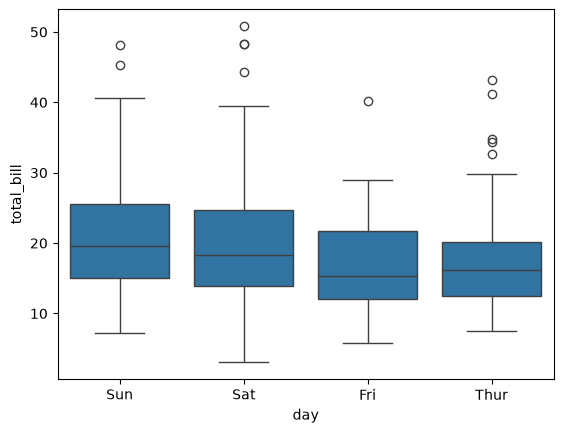

In [101]:
order = ["Sun", "Sat", "Fri", "Thur"]
sns.boxplot(data=df, x="day", y="total_bill", order=order)


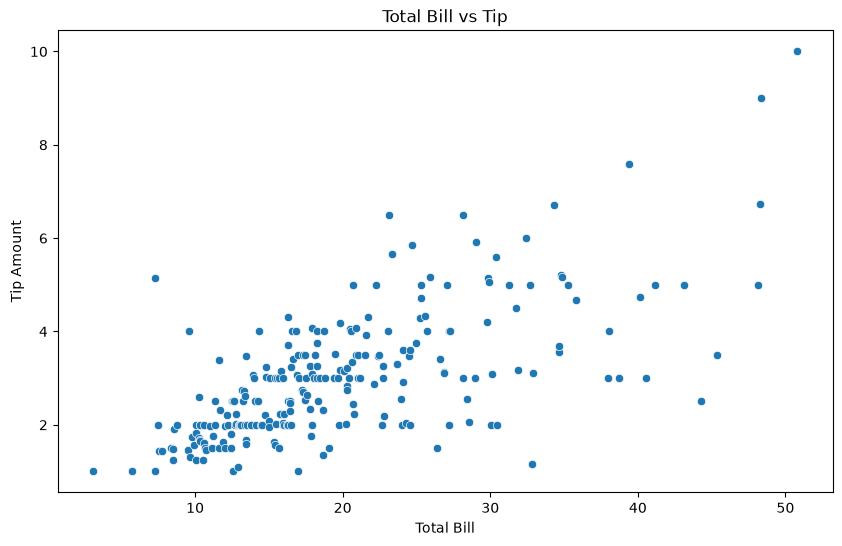

In [105]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=df, x="total_bill", y="tip", ax=ax)

ax.set_title("Total Bill vs Tip")
ax.set_xlabel("Total Bill")
ax.set_ylabel("Tip Amount")
plt.show()


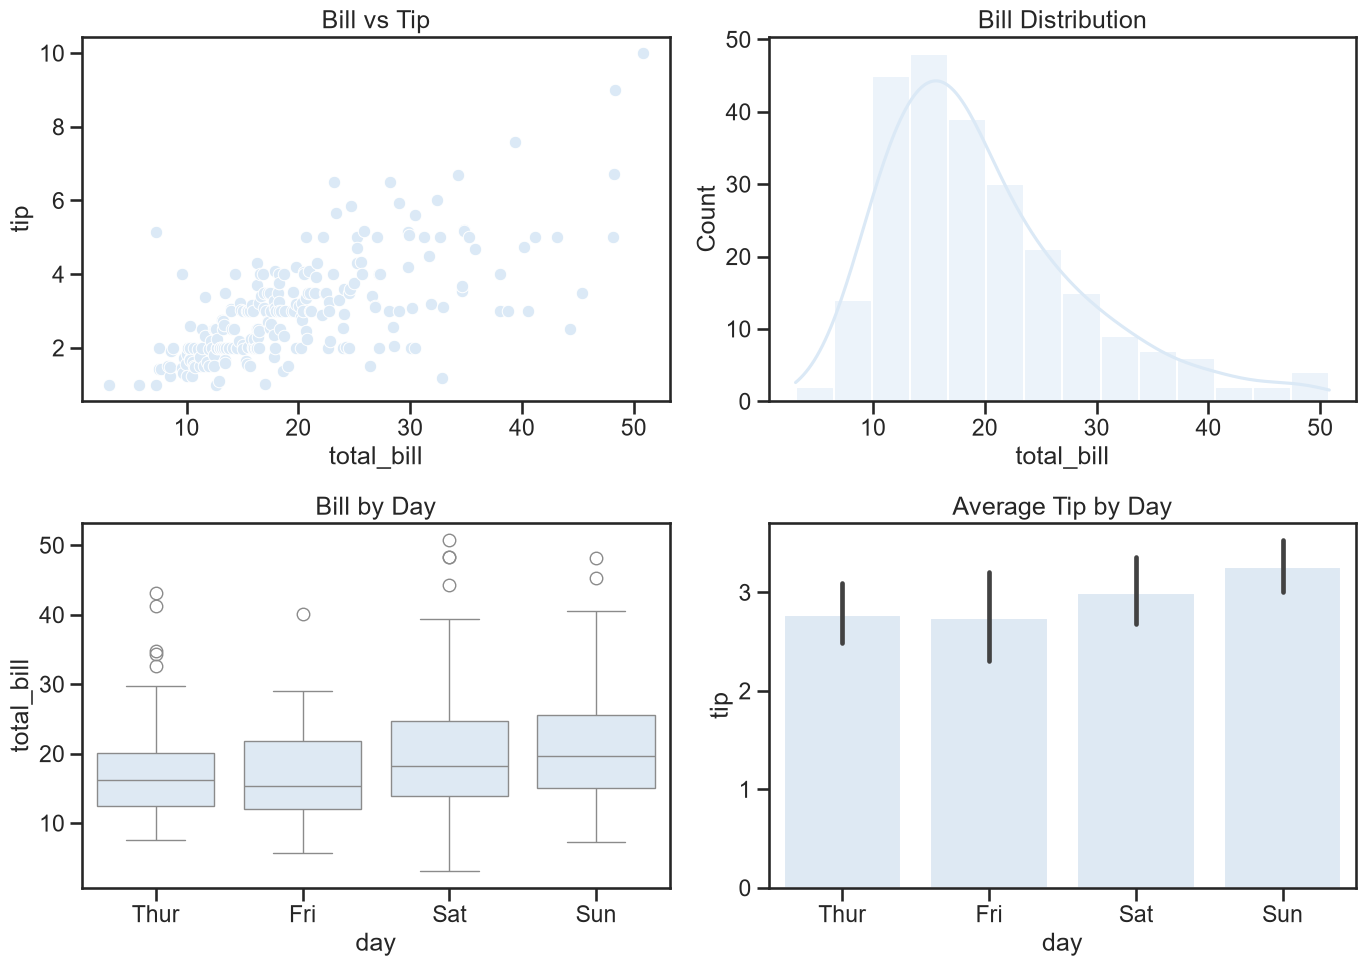

In [115]:
sns.set_theme(style="ticks", context="talk", palette="colorblind")
sns.set_palette( palette='Blues')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=df, x="total_bill", y="tip", ax=axes[0, 0])
axes[0, 0].set_title("Bill vs Tip")

sns.histplot(data=df, x="total_bill", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Bill Distribution")

sns.boxplot(data=df, x="day", y="total_bill", ax=axes[1, 0])
axes[1, 0].set_title("Bill by Day")

sns.barplot(data=df, x="day", y="tip", ax=axes[1, 1])
axes[1, 1].set_title("Average Tip by Day")

plt.tight_layout()
plt.show()


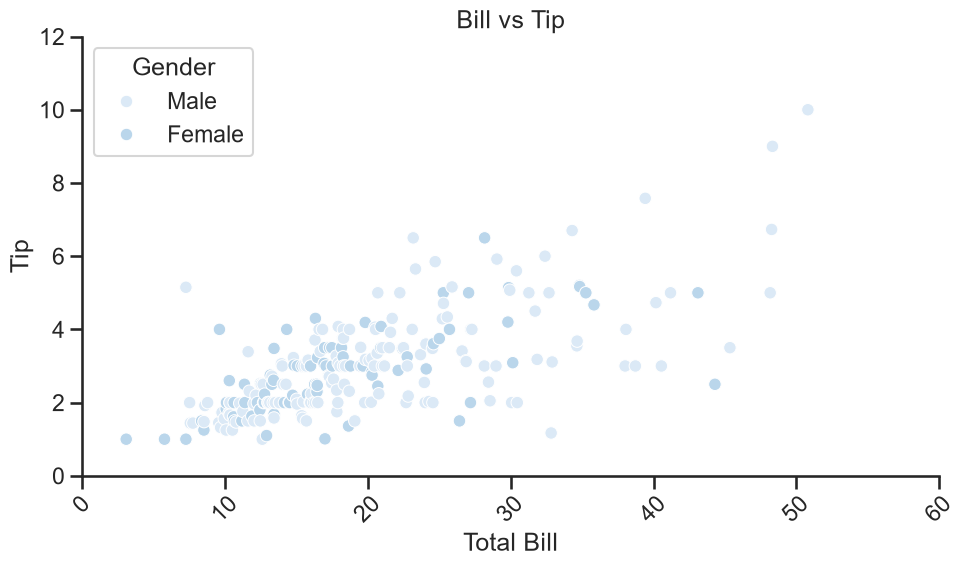

In [119]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="sex", ax=ax)

ax.set(title="Bill vs Tip", xlabel="Total Bill", ylabel="Tip",
       xlim=(0, 60), ylim=(0, 12))                       # axis limits
ax.tick_params(axis="x", rotation=45)                    # rotate long labels
ax.legend(title="Gender", loc="upper left")              # reposition legend
sns.despine(ax=ax)                                       # remove top/right borders
plt.tight_layout()
plt.show()
fig.savefig("bill_vs_tip.png", dpi=1200, bbox_inches="tight")


In [120]:
df

,total_bill,tip,sex,smoker,day,time,size,price_range
0,3.07,1.00,Female,Yes,Sat,Dinner,1,0-10
1,5.75,1.00,Female,Yes,Fri,Dinner,2,0-10
2,7.25,1.00,Female,No,Sat,Dinner,1,0-10
3,7.25,5.15,Male,Yes,Sun,Dinner,2,0-10
4,7.51,2.00,Male,No,Thur,Lunch,2,0-10
...,...,...,...,...,...,...,...,...
239,45.35,3.50,Male,Yes,Sun,Dinner,3,40-50
240,48.17,5.00,Male,No,Sun,Dinner,6,40-50
241,48.27,6.73,Male,No,Sat,Dinner,4,40-50
242,48.33,9.00,Male,No,Sat,Dinner,4,40-50
